In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ambiance import Atmosphere

## Data Import

The data for the rockets $C_{d,rocket}$ is imported from RASAero II. The data gives $C_{d,rocket}$ with respect to Mach number $(M)$ for altitudes $0ft$ to $12,000ft$ in $1000ft$ increments. The data is then ploted below.


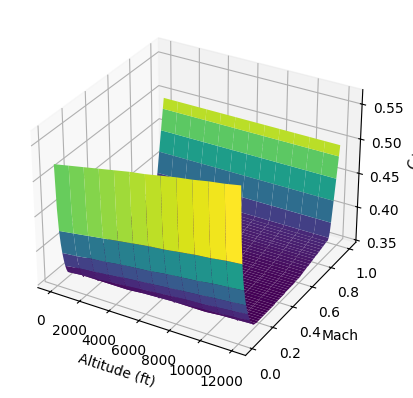

In [20]:
data = pd.read_excel(r'C:\Users\101163874\Documents\MARS\RASAeroII Cd data.xlsx', header=None, skiprows=3).to_numpy(float)
mach = data[:, 0]
cd = data[:, 1:]
alt = np.arange(0, 13000, 1000)

A, M = np.meshgrid(alt, mach)
ax = plt.figure().add_subplot(projection='3d')
ax.plot_surface(A, M, cd, cmap='viridis')
ax.set_xlabel('Altitude (ft)')
ax.set_ylabel('Mach')
ax.set_zlabel('$C_d$')
plt.show()

1.8542323467016935
27.28582955198014
6.957636034528764
The maximum pedal angle is 51.053775474704175 degrees
Length outside the rocket: 1.5 in


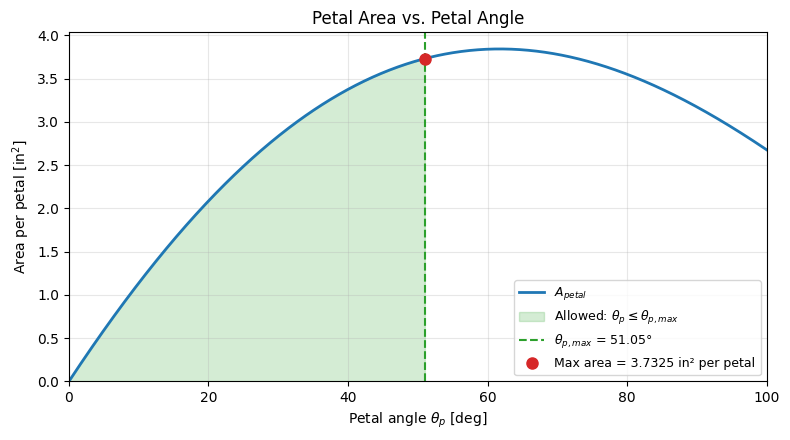

Maximum pedal angle: 51.054 deg
Maximum pedal width: 2.663 in
Max area per petal:  3.7325 in^2
Total area (3):      11.1974 in^2
w = 2.6632 in | h_max = 1.5000 in | N = 3 | theta_p = 51.05 deg


In [21]:
# ---- Load optimized petal dimensions from Petal_Area_Optimization -------------
PIPELINE = True                          # quiets the optimization notebook's printouts/plots
%run Petal_Area_Optimization.ipynb       # -> PETAL_COUNT, PETAL_WIDTH, PETAL_H_MAX, PETAL_AREA, ...

X     = 2.22                             # [m] petal station from nose tip
A_REF = 0.01935932                       # [m^2] RASAero II reference area (30.007 in^2)

print(f"w = {PETAL_WIDTH/0.0254:.4f} in | h_max = {PETAL_H_MAX/0.0254:.4f} in | "
      f"N = {PETAL_COUNT} | theta_p = {np.rad2deg(PETAL_ANGLE):.2f} deg")

### $\Delta C_d$ for Pedals
---

#### 1.) Incompressible drag coeficient for a plate $(C_{D,p0})$ [1, Ch.3]:

$$
C_{D,p0} \approx
\begin{cases}
1.17, & AR = 1 \\
1.20\text{--}1.25, & AR \approx 2\text{--}5
\end{cases}
$$

Where $AR$ is the aspect ratio and $AR = \frac{w}{h}$

#### 2.) Compressibiity Factor $(f(M))$ [1, ]:

$$
f(M) = \frac{q_0}{q_\infty} = \frac{2}{\gamma M^2} [(1+\frac{\gamma - 1}{2} M^2)^{\frac{\gamma}{\gamma - 1}} - 1] \approx 1 + \frac{M^2}{4} + \frac{M^4}{40}
$$

#### 3.) Boundary-Layer Immersion Factor $(\eta_{BL} (M, A_{act}))$ [1, Ch.5]:

$$
\eta_{BL} (M, A_{act}) = 
\begin{cases}
\frac{7}{9} (\frac{A_{act}}{w\delta})^{2/7}, & A_{act} \geq w\delta \\
1 - \frac{2w\delta}{9A_{act}} , & A_{act} > w\delta
\end{cases}
$$

Where $\delta(x)$ is the boundary layer height at the location of the pedals $(x)$ from the rockets nose:

$$
\delta(x) = \frac{0.37x}{Re^{1/5}}
$$

#### 4.) The final form for the $\Delta C_D$ is given by:

$$
\Delta C_D = 

N K_{int} \frac{A_{act}}{A_{ref}}

\frac{2}{\gamma M^2} [(1+\frac{\gamma - 1}{2} M^2)^{\frac{\gamma}{\gamma - 1}} - 1]

\begin{cases}
\frac{7}{9} (\frac{A_{act}}{w\delta})^{2/7}, & A_{act} \leq w\delta \\
1 - \frac{2w\delta}{9A_{act}} , & A_{act} > w\delta
\end{cases}

\begin{cases}
1.17, & AR = 1 \\
1.20\text{--}1.25, & AR \approx 2\text{--}5
\end{cases}
$$

Where:
| Symbol | Meaning |
|---|---|
| $N$ | Number of brake pedals |
| $A_{ref}$ | Exposed area of one plate (normal to the flow) |
| $A_{ref}$ | RASAeroII's reference area |
| $C_{D,p0}$ | Incompressible drag coefficient of a flat plate normal to the flow |
| $f(M)$ | Compressibility factor |
| $\eta_{BL}$ | Boundary-layer immersion factor |
| $K_{int}$ | Interference factor, $\approx 1.0$–$1.2$ |


#### With this information the following function is defined:

In [22]:
def pedal_dcd(mach, w, h_max, act, x, alt):
    # w, h_max, x in meters, alt in ft, act from 0 to 1
    atm = Atmosphere(alt * 0.3048)
    T = atm.temperature[0]
    rho = atm.density[0]
    mu = atm.dynamic_viscosity[0]
    a = atm.speed_of_sound[0]
    g = a**2 / (287.05287 * T)

    h = act * h_max
    A = w * h
    AR = (2*h) / w

    if AR < 2:
        Cd0 = 1.17 + 0.03 * (AR - 1)
    elif AR <= 5:
        Cd0 = 1.20 + 0.05 * (AR - 2) / 3
    else:
        Cd0 = 1.25

    dCd = np.zeros(len(mach))
    for i, M in enumerate(mach):
        V = M * a
        f = 2 / (g * M**2) * ((1 + (g - 1) / 2 * M**2) ** (g / (g - 1)) - 1)
        delta = 0.37 * x / (rho * V * x / mu) ** 0.2

        if A <= w * delta:
            eta = 7/9 * (A / (w * delta)) ** (2/7)
        else:
            eta = 1 - 2 * w * delta / (9 * A)

        dCd[i] = Cd0 * f * eta

    return dCd

### Total $C_D$ Approximation:

The total drag for the rocket is found by simply adding the $C_D$ from the above function to the data for $C_D$ from the RASAeroII simulations

In [23]:
def total_cd(w, h_max, x, n, A_ref, mach, alt, cd_rocket):
    acts = np.arange(0.05, 1.0001, 0.05)
    total = np.zeros((len(alt), len(acts), len(mach)))

    for i, z in enumerate(alt):
        for j, act in enumerate(acts):
            dCd = pedal_dcd(mach, w, h_max, act, x, z) * n * act * w * h_max / A_ref
            total[i, j] = cd_rocket[:, i] + dCd

        """ACT, M = np.meshgrid(acts, mach, indexing='ij')
        ax = plt.figure().add_subplot(projection='3d')
        s = ax.plot_surface(ACT, M, total[i], cmap='viridis', alpha=0.7)
        ax.scatter(ACT, M, total[i], s=5)
        plt.colorbar(s)
        ax.set_title(f'Total $C_d$ at {z:.0f} ft')
        ax.set_xlabel('Deployment Level')
        ax.set_ylabel('Mach')
        ax.set_zlabel('$C_d$')
        plt.show()"""

        

    return acts, total

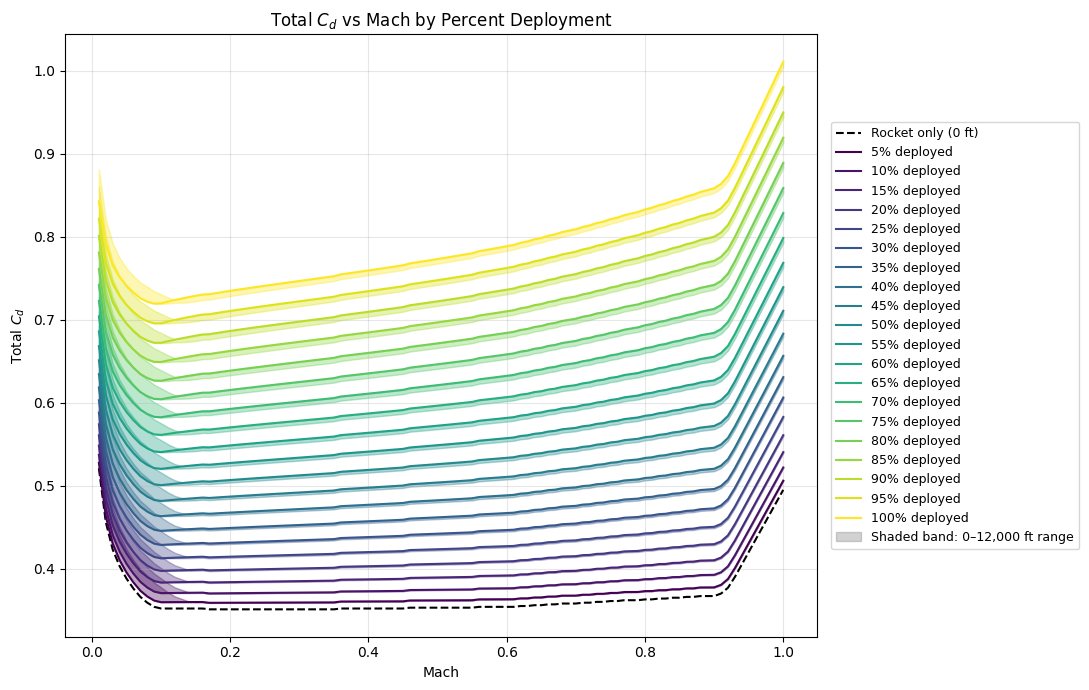

In [24]:
# A_ref = 30.007 [in^2] = 0.01935932 [m^2]
# w = 2.663 [in] = 0.0676402 [m]
# h_max = 1.5 [in] = 0.0381


acts, total = total_cd(w=PETAL_WIDTH, h_max=PETAL_H_MAX, x=X, n=PETAL_COUNT, A_ref=A_REF,
                       mach=mach, alt=alt, cd_rocket=cd)


from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 7))
colors = plt.cm.viridis(np.linspace(0, 1, len(acts)))
ax.plot(mach, cd[:, 0], 'k--', label='Rocket only (0 ft)')
for j, c in enumerate(colors):
    ax.fill_between(mach, total[:, j].min(axis=0), total[:, j].max(axis=0), color=c, alpha=0.35)
    ax.plot(mach, total[0, j], color=c, label=f'{acts[j]*100:.0f}% deployed')


handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='gray', alpha=0.35)]
labels += ['Shaded band: 0–12,000 ft range']
ax.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=9)

ax.set_xlabel('Mach')
ax.set_ylabel('Total $C_d$')
ax.set_title('Total $C_d$ vs Mach by Percent Deployment')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:
"""w, h_max, x, n, A_ref = PETAL_WIDTH, PETAL_H_MAX, X, PETAL_COUNT, A_REF

levels = np.round(np.arange(0, 1.0001, 0.025), 3)   # 0 – 100 % in 2.5 % steps (41 levels)
machs  = np.round(np.arange(0, 1.0001, 0.05), 2)    # Mach 0 – 1 in 0.05 steps (21 values)

rows = [(act, M, 0.0 if act == 0 or M == 0 else
         pedal_dcd([M], w, h_max, act, x, alt_ft)[0] * n * act * w * h_max / A_ref)
        for act in levels for M in machs]

pd.DataFrame(rows, columns=["deployment_level", "mach", "cd"]).to_excel("airbrake_cd.xlsx", index=False)"""

'w, h_max, x, n, A_ref = PETAL_WIDTH, PETAL_H_MAX, X, PETAL_COUNT, A_REF\n\nlevels = np.round(np.arange(0, 1.0001, 0.025), 3)   # 0 – 100 % in 2.5 % steps (41 levels)\nmachs  = np.round(np.arange(0, 1.0001, 0.05), 2)    # Mach 0 – 1 in 0.05 steps (21 values)\n\nrows = [(act, M, 0.0 if act == 0 or M == 0 else\n         pedal_dcd([M], w, h_max, act, x, alt_ft)[0] * n * act * w * h_max / A_ref)\n        for act in levels for M in machs]\n\npd.DataFrame(rows, columns=["deployment_level", "mach", "cd"]).to_excel("airbrake_cd.xlsx", index=False)'